# M1-INF4 — Python Workshop for Data Analysis
## Session 5 — Data Integration Case Study

### A retail decision supported by reliable data
You are a small analytics team working for **Campus Tech**, a fictional retailer of computer accessories and equipment. The manager wants to compare stores before deciding where to investigate further.

> “The store with the highest total sales is our best-performing store. We should copy its approach everywhere.”

**Your mission:** integrate three sources, assess this claim and deliver an evidence-based recommendation.

This is a synthesis project. Use the pandas and Matplotlib techniques from Sessions 1–4. No new library or advanced modelling is required.

**All data are synthetic. Some records deliberately contain quality issues for training.** Findings describe this supplied sample, not a real company.

### What the data represent
The intended scope is **1–28 April 2025 inclusive**. This is an extract of completed orders, **not a complete record of all activity**. Coverage can differ between stores. A day absent from the extract is not evidence of zero sales or store closure.

| File | One row represents | Expected key | Purpose |
|---|---|---|---|
| `case_sales.csv` | One completed order for one product, possibly several units | `order_id` | Recorded quantity and unit selling price |
| `case_stores.csv` | One store | `store_id` | Store name, city and format |
| `case_products.csv` | One product | `product_id` | Product name and category |

Each order concerns **one product only**, so one valid order row is one order, not a line in a multi-product basket. The price is the final selling price per unit in EUR, after discounts and excluding VAT. Returns and cancellations are outside this extract.

Revenue per order = quantity × unit selling price. **Revenue is not profit**: costs, staffing, opening hours and customer traffic are unavailable.

The reference files should have unique keys, but this must be checked. Repeated store or product IDs in the sales file are normal.

### Data dictionary
| Field | Meaning and rule |
|---|---|
| `order_id` | Order identifier, required and unique after removing exact repeated records |
| `date` | Order date, expected format `YYYY-MM-DD`, within the study window |
| `store_id`, `product_id` | Reference keys; trim spaces and normalise case before joining |
| `quantity` | Positive whole number of units |
| `unit_price_eur` | Positive numeric unit price; a decimal comma may occur |
| `store_name`, `city`, `store_format` | Store attributes; “Small”/“Large” describes format, not observed floor area |
| `product_name`, `category` | Product attributes |

**Quality policy:** keep raw objects unchanged. Remove exact duplicate rows with an audit count. Convert invalid dates/numbers to missing values. Keep invalid or unmatched records in review tables, without inventing replacements. Do not remove a large but valid order simply because it is unusual. If duplicate reference keys disagree, investigate rather than arbitrarily keeping the first row.

### Files and group deliverable
Place this notebook in `notebooks/` and the three CSV files in the neighbouring `data/` folder. You may also put the CSV files beside the notebook.

Submit one completed notebook per group, the exported summary tables and three labelled figures. Record group members below. Divide the work, then review the entire analysis together: **every member must be able to explain the data unit, cleaning choices, joins and conclusions**.

Group members: *Léo Ajas, André Margaryan, Alexis Hummel, Manil Benmoussa*

The sections below form one continuous analysis. Each checkpoint is a review of your own results, not a separate dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('../data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in
    ['case_sales.csv', 'case_stores.csv', 'case_products.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three case_*.csv files in data/ or beside this notebook.')
OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(exist_ok=True)

sales_raw = pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string')
stores_raw = pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string')
products_raw = pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string')
for name, frame in [('Sales', sales_raw), ('Stores', stores_raw), ('Products', products_raw)]:
    print(name, frame.shape)
    display(frame.head())

Matplotlib is building the font cache; this may take a moment.


Sales (252, 6)


,order_id,date,store_id,product_id,quantity,unit_price_eur
0,O0001,2025-04-21,s1,P02,3,19.90
1,O0002,2025-04-14,S1,p02,2,39.90
2,O0003,2025-04-14,S1,P04,1,"179,00"
3,O0004,2025-04-31,S1,P03,1,179.00
4,O0005,2025-04-09,S1,P02,two,19.90


Stores (4, 4)


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Products (7, 3)


,product_id,product_name,category
0,P01,Keyboard,Accessories
1,P02,Mouse,Accessories
2,P03,Monitor,Screens
3,P04,Headset,Audio
4,P05,Webcam,Video


## 1. Understand and audit the sources
1. Report row and column counts, missing values and exact duplicate counts for each source.
2. Check the expected keys. Explain why repeated `store_id` values are acceptable in sales but potentially dangerous in stores.
3. Write the observation unit and the proposed join keys before joining anything.

**Checkpoint:** your audit should distinguish missing data, repeated records and normal repeated foreign keys.

In [2]:

sources = {'Sales': sales_raw, 'Stores': stores_raw, 'Products': products_raw}
expected_keys = {'Sales': 'order_id', 'Stores': 'store_id', 'Products': 'product_id'}

audit_rows = []
for name, df in sources.items():
    key = expected_keys[name]
    audit_rows.append({
        'source': name,
        'rows': df.shape[0],
        'columns': df.shape[1],
        'total_missing_cells': int(df.isna().sum().sum()),
        'exact_duplicate_rows': int(df.duplicated().sum()),
        'key': key,
        'key_missing': int(df[key].isna().sum()),
        'key_distinct': int(df[key].nunique(dropna=True)),
        'key_repeated_values': int(df[key].dropna().duplicated().sum()),
    })
audit = pd.DataFrame(audit_rows)
display(audit)

for name, df in sources.items():
    print(f'\n--- {name}: missing values per column ---')
    print(df.isna().sum().to_string())
    print(f'\n--- {name}: dtypes / columns ---')
    print(list(df.columns))

for name in ['Stores', 'Products']:
    df = sources[name]
    key = expected_keys[name]
    rep = df[df[key].duplicated(keep=False) & df[key].notna()].sort_values(key)
    print(f'\n--- {name}: rows sharing the same {key} ({len(rep)}) ---')
    display(rep)

rep_orders = sales_raw[sales_raw['order_id'].duplicated(keep=False) & sales_raw['order_id'].notna()]
print(f'\n--- Sales: rows sharing an order_id ({len(rep_orders)}) ---')
display(rep_orders.sort_values('order_id').head(20))


print('\nOrders per raw store_id in sales (normal repetition of a foreign key):')
print(sales_raw['store_id'].value_counts(dropna=False).to_string())


print('\nDistinct raw store_id values in sales:', sorted(sales_raw['store_id'].dropna().unique().tolist()))
print('Distinct raw store_id values in stores:', sorted(stores_raw['store_id'].dropna().unique().tolist()))
print('\nSample of raw dates:', sales_raw['date'].dropna().sample(min(10, sales_raw['date'].notna().sum()), random_state=0).tolist())
print('Sample of raw prices:', sales_raw['unit_price_eur'].dropna().sample(min(10, sales_raw['unit_price_eur'].notna().sum()), random_state=0).tolist())
print('Sample of raw quantities:', sales_raw['quantity'].dropna().unique()[:20].tolist())

,source,rows,columns,total_missing_cells,exact_duplicate_rows,key,key_missing,key_distinct,key_repeated_values
0,Sales,252,6,1,2,order_id,0,250,2
1,Stores,4,4,0,0,store_id,0,4,0
2,Products,7,3,0,1,product_id,0,6,1



--- Sales: missing values per column ---
order_id          0
date              0
store_id          0
product_id        0
quantity          0
unit_price_eur    1

--- Sales: dtypes / columns ---
['order_id', 'date', 'store_id', 'product_id', 'quantity', 'unit_price_eur']

--- Stores: missing values per column ---
store_id        0
store_name      0
city            0
store_format    0

--- Stores: dtypes / columns ---
['store_id', 'store_name', 'city', 'store_format']

--- Products: missing values per column ---
product_id      0
product_name    0
category        0

--- Products: dtypes / columns ---
['product_id', 'product_name', 'category']

--- Stores: rows sharing the same store_id (0) ---


,store_id,store_name,city,store_format



--- Products: rows sharing the same product_id (2) ---


,product_id,product_name,category
0,P01,Keyboard,Accessories
6,P01,Keyboard,Accessories



--- Sales: rows sharing an order_id (4) ---


,order_id,date,store_id,product_id,quantity,unit_price_eur
20,O0021,2025-04-10,S1,P01,1,39.90
250,O0021,2025-04-10,S1,P01,1,39.90
90,O0091,2025-04-10,S1,P02,1,19.90
251,O0091,2025-04-10,S1,P02,1,19.90



Orders per raw store_id in sales (normal repetition of a foreign key):
store_id
S1      100
S2       70
S3       50
S4       30
 s1       1
S99       1

Distinct raw store_id values in sales: [' s1 ', 'S1', 'S2', 'S3', 'S4', 'S99']
Distinct raw store_id values in stores: ['S1', 'S2', 'S3', 'S4']

Sample of raw dates: ['2025-04-13', '2025-04-28', '2025-04-16', '2025-04-08', '2025-04-11', '2025-04-20', '2025-04-06', '2025-04-05', '2025-04-21', '2025-04-06']
Sample of raw prices: ['59.90', '19.90', '29.90', '179.00', '179.00', '39.90', '19.90', '39.90', '19.90', '19.90']
Sample of raw quantities: ['3', '2', '1', 'two', '-1', '1.5']


**Notre interprétation**

Une ligne de `sales_raw` représente une commande d'un seul produit, qui peut contenir plusieurs unités. Une ligne de `stores_raw` représente un magasin et une ligne de `products_raw` représente un produit.

On relie les ventes aux magasins avec `store_id`, et aux produits avec `product_id`. Plusieurs commandes peuvent concerner le même magasin : les répétitions de `store_id` sont donc normales dans les ventes. Dans la table des magasins, chaque identifiant doit être unique pour éviter de multiplier les commandes lors de la jointure.


## 2. Prepare reliable tables
Create working copies. Apply the quality policy above.

1. Count and remove **exact** duplicate records in all three tables.
2. Normalise identifiers, parse dates and convert the two numeric fields. Handle decimal commas.
3. Flag missing IDs, failed conversions, non-positive prices, quantities that are not positive integers, and dates outside the study window.
4. Produce `sales_valid` and `sales_review`. Keep the rejected records and the reason flags.
5. Validate unique, non-missing reference keys and unique valid order IDs.

**Checkpoint:** input rows = exact duplicates removed + invalid rows retained for review + valid rows. Multiple reason flags can describe the same rejected row, so do not sum flags as if they were distinct rows.

In [3]:
# Clean and validate without changing the raw objects
sales_dedup = sales_raw.drop_duplicates()
stores_dedup = stores_raw.drop_duplicates()
products_dedup = products_raw.drop_duplicates()

exact_duplicates_sales = len(sales_raw) - len(sales_dedup)
exact_duplicates_stores = len(stores_raw) - len(stores_dedup)
exact_duplicates_products = len(products_raw) - len(products_dedup)

sales_clean = sales_dedup.copy()
stores_clean = stores_dedup.copy()
products_clean = products_dedup.copy()

for col in ['order_id', 'store_id', 'product_id']:
    if col in sales_clean.columns:
        sales_clean[col] = sales_clean[col].str.strip().str.upper()

stores_clean['store_id'] = stores_clean['store_id'].str.strip().str.upper()
products_clean['product_id'] = (
    products_clean['product_id'].str.strip().str.upper()
)

sales_clean['unit_price_eur'] = pd.to_numeric(
    sales_clean['unit_price_eur'].str.replace(',', '.'), errors='coerce'
)

sales_clean['quantity_num'] = pd.to_numeric(
    sales_clean['quantity'], errors='coerce'
)

sales_clean['date_parsed'] = pd.to_datetime(
    sales_clean['date'], format='%Y-%m-%d', errors='coerce'
)

flags = pd.DataFrame(index=sales_clean.index)

flags['flag_missing_id'] = (
    sales_clean['order_id'].isna()
    | sales_clean['store_id'].isna()
    | sales_clean['product_id'].isna()
)

flags['flag_invalid_price_format'] = sales_clean['unit_price_eur'].isna()
flags['flag_invalid_quantity_format'] = sales_clean['quantity_num'].isna()
flags['flag_invalid_date_format'] = sales_clean['date_parsed'].isna()

flags['flag_non_positive_price'] = (
    sales_clean['unit_price_eur'].notna() & (sales_clean['unit_price_eur'] <= 0)
)
flags['flag_invalid_quantity_value'] = sales_clean['quantity_num'].notna() & (
    (sales_clean['quantity_num'] <= 0)
    | (sales_clean['quantity_num'] % 1 != 0)
)

start_date = pd.Timestamp('2025-04-01')
end_date = pd.Timestamp('2025-04-28')
flags['flag_out_of_window'] = sales_clean['date_parsed'].notna() & (
    (sales_clean['date_parsed'] < start_date)
    | (sales_clean['date_parsed'] > end_date)
)

sales_clean['is_invalid'] = flags.any(axis=1)

sales_valid = sales_clean[~sales_clean['is_invalid']].copy()
sales_valid['quantity'] = sales_valid['quantity_num'].astype(int)
sales_valid['date'] = sales_valid['date_parsed'].dt.strftime('%Y-%m-%d')
sales_valid = sales_valid[
    ['order_id', 'date', 'store_id', 'product_id', 'quantity', 'unit_price_eur']
]

# Ajouter les raisons avant de sélectionner les lignes à revoir
for col in flags.columns:
    sales_clean[col] = flags[col]

sales_review = sales_clean[sales_clean['is_invalid']].copy()

assert sales_valid['order_id'].is_unique, (
    'Erreur : doublons de order_id détectés dans sales_valid !'
)

# Vérifier les clés des tables de référence
assert stores_clean['store_id'].notna().all() and stores_clean['store_id'].is_unique
assert products_clean['product_id'].notna().all() and products_clean['product_id'].is_unique

print(f'Lignes brutes initiales : {len(sales_raw)}')
print(f'Doublons exacts supprimés dans Sales : {exact_duplicates_sales}')
print(f'Doublons exacts supprimés dans Stores : {exact_duplicates_stores}')
print(f'Doublons exacts supprimés dans Products : {exact_duplicates_products}')
print(f'Lignes rejetées (sales_review) : {len(sales_review)}')
print(f'Lignes valides (sales_valid) : {len(sales_valid)}')
print(
    'Total reconstitué :'
    f' {len(sales_raw) - exact_duplicates_sales} ='
    f' {len(sales_review) + len(sales_valid)}'
)

Lignes brutes initiales : 252
Doublons exacts supprimés dans Sales : 2
Doublons exacts supprimés dans Stores : 0
Doublons exacts supprimés dans Products : 1
Lignes rejetées (sales_review) : 7
Lignes valides (sales_valid) : 243
Total reconstitué : 250 = 250


**Notre interprétation**

Nous avons supprimé 2 doublons exacts dans les ventes et 1 dans les produits ; aucun dans les magasins. Nous avons retiré les espaces et harmonisé les majuscules des identifiants, puis remplacé les virgules décimales des prix par des points pour les convertir en nombres.

Après dédoublonnage, 7 lignes sont mises en revue : une date impossible, une quantité non numérique, un prix manquant, une quantité négative, un prix nul, une quantité non entière et une date hors période. Les 243 autres commandes sont conservées avant les jointures. Les commandes élevées mais valides sont gardées et les données brutes restent inchangées.


## 3. Integrate and reconcile
1. Join `sales_valid` to stores with a **left join**, `validate="many_to_one"` and an indicator. Inspect unmatched keys.
2. Join that result to products with the same controls. Use a different indicator name, or rename/remove the first indicator before the second join.
3. Check that neither join changes the row count.
4. Keep orders missing either reference in `integration_review`. Create `analysis` using orders matched to **both** references.
5. Present a reconciliation table from raw input to the final analytical population.

**Checkpoint:** never interpret an unknown product as zero revenue, and never allow a duplicated reference key to multiply orders. State how many orders the analysis excludes.

In [4]:
# Join the sources and audit coverage
sales_stores = pd.merge(
    sales_valid,
    stores_clean,
    on='store_id',
    how='left',
    validate='many_to_one',
    indicator='_merge_store'
)

unmatched_stores = sales_stores[sales_stores['_merge_store'] == 'left_only']
print(f"Commandes sans magasin associé : {len(unmatched_stores)}")
if len(unmatched_stores) > 0:
    print("Identifiants de magasins non trouvés :", unmatched_stores['store_id'].unique())

sales_full = pd.merge(
    sales_stores,
    products_clean,
    on='product_id',
    how='left',
    validate='many_to_one',
    indicator='_merge_product'
)

unmatched_products = sales_full[sales_full['_merge_product'] == 'left_only']
print(f"Commandes sans produit associé : {len(unmatched_products)}")
if len(unmatched_products) > 0:
    print("Identifiants de produits non trouvés :", unmatched_products['product_id'].unique())


assert len(sales_stores) == len(sales_valid), "Erreur : La jointure stores a modifié le nombre de lignes !"
assert len(sales_full) == len(sales_valid), "Erreur : La jointure products a modifié le nombre de lignes !"


is_integrated = (sales_full['_merge_store'] == 'both') & (sales_full['_merge_product'] == 'both')

integration_review = sales_full[~is_integrated].copy()

analysis = sales_full[is_integrated].copy()
analysis = analysis.drop(columns=['_merge_store', '_merge_product'])


reconciliation_data = [
    {"Etape": "Lignes initiales (case_sales.csv)", "Nombre de lignes": len(sales_raw)},
    {"Etape": "Moins : Doublons exacts", "Nombre de lignes": -exact_duplicates_sales},
    {"Etape": "Moins : Enregistrements invalides (sales_review)", "Nombre de lignes": -len(sales_review)},
    {"Etape": "Commandes valides (sales_valid)", "Nombre de lignes": len(sales_valid)},
    {"Etape": "Moins : Magasin inconnu / non référencé", "Nombre de lignes": -len(unmatched_stores)},
    {"Etape": "Moins : Produit inconnu / non référencé", "Nombre de lignes": -len(sales_full[sales_full['_merge_product'] == 'left_only'])},
    {"Etape": "Population finale d'analyse (analysis)", "Nombre de lignes": len(analysis)}
]

reconciliation = pd.DataFrame(reconciliation_data)

print("\n=== Table de réconciliation ===")
display(reconciliation)
print(f"\nNombre total de commandes exclues de l'analyse finale : {len(sales_raw) - len(analysis)} sur {len(sales_raw)}")

Commandes sans magasin associé : 1
Identifiants de magasins non trouvés : <StringArray>
['S99']
Length: 1, dtype: string
Commandes sans produit associé : 1
Identifiants de produits non trouvés : <StringArray>
['P99']
Length: 1, dtype: string

=== Table de réconciliation ===


,Etape,Nombre de lignes
0,Lignes initiales (case_sales.csv),252
1,Moins : Doublons exacts,-2
2,Moins : Enregistrements invalides (sales_review),-7
3,Commandes valides (sales_valid),243
4,Moins : Magasin inconnu / non référencé,-1
5,Moins : Produit inconnu / non référencé,-1
6,Population finale d'analyse (analysis),241



Nombre total de commandes exclues de l'analyse finale : 11 sur 252


**Notre interprétation**

Les jointures à gauche conservent toutes les commandes valides et permettent de repérer les références absentes. Une jointure interne aurait supprimé ces commandes sans les montrer. Une commande concerne le magasin inconnu `S99` et une autre le produit inconnu `P99` : elles sont conservées dans `integration_review`. Il reste 241 commandes pour l'analyse et les jointures n'ont pas multiplié les lignes.


## 4. Build indicators that answer the question
For each order in `analysis`, calculate `revenue_eur`.

Create `store_summary` with, for each store:
- order count and total units;
- total revenue (EUR);
- mean and median revenue per order (EUR).

Also create a revenue summary by product category and a daily revenue table for each store. Check that the totals reconcile with the order-level revenue.

Compare the store with the highest total revenue to the store with the highest mean revenue per order. Do they coincide? Explain the role of order counts and product mix.

**Important:** `quantity` counts units, not orders. Mean revenue per order = total revenue / number of orders. Round for presentation, not before aggregation. Avoid calling this a profitability or productivity ranking.

In [5]:
# Calculer le revenu de chaque commande et les indicateurs agrégés

analysis = analysis.copy()
analysis["date"] = pd.to_datetime(analysis["date"], errors="coerce")
analysis["quantity"] = pd.to_numeric(analysis["quantity"], errors="coerce")
analysis["unit_price_eur"] = pd.to_numeric(analysis["unit_price_eur"], errors="coerce")
analysis["revenue_eur"] = analysis["quantity"] * analysis["unit_price_eur"]

# Résumé par magasin
store_keys = ["store_id", "store_name", "city", "store_format"]
store_summary = (
    analysis.groupby(store_keys, dropna=False)
    .agg(
        order_count=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_revenue_eur=("revenue_eur", "sum"),
        mean_order_revenue_eur=("revenue_eur", "mean"),
        median_order_revenue_eur=("revenue_eur", "median"),
    )
    .reset_index()
    .sort_values("total_revenue_eur", ascending=False)
)
store_summary[["total_revenue_eur", "mean_order_revenue_eur",
               "median_order_revenue_eur"]] = store_summary[
    ["total_revenue_eur", "mean_order_revenue_eur",
     "median_order_revenue_eur"]
].round(2)

# Résumé du chiffre d'affaires par catégorie de produit
category_summary = (
    analysis.groupby("category", dropna=False)
    .agg(
        order_count=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_revenue_eur=("revenue_eur", "sum"),
    )
    .reset_index()
    .sort_values("total_revenue_eur", ascending=False)
)
category_summary["total_revenue_eur"] = category_summary["total_revenue_eur"].round(2)

# Revenu quotidien par magasin
daily_revenue = (
    analysis.groupby(["date", "store_id", "store_name"], dropna=False)
    ["revenue_eur"].sum()
    .reset_index()
)
calendar = pd.date_range("2025-04-01", "2025-04-28", freq="D")
store_labels = stores_clean[["store_id", "store_name"]].drop_duplicates()
full_calendar = pd.MultiIndex.from_product(
    [calendar, store_labels["store_id"].drop_duplicates()],
    names=["date", "store_id"]
).to_frame(index=False)
full_calendar = full_calendar.merge(store_labels, on="store_id", how="left")
daily_revenue = full_calendar.merge(
    daily_revenue, on=["date", "store_id", "store_name"], how="left"
)
# Les jours sans commande enregistrée restent Nan

# Contrôle de cohérence des revenus
total_order_revenue = analysis["revenue_eur"].sum()
total_store_revenue = analysis.groupby("store_id")["revenue_eur"].sum().sum()
total_category_revenue = analysis.groupby("category", dropna=False)["revenue_eur"].sum().sum()

print("Résumé par magasin (montants en EUR) :")
display(store_summary)
print("Résumé par catégorie (montants en EUR) :")
display(category_summary)
print("Extrait du revenu quotidien par magasin :")
display(daily_revenue.head(10))

print(f"Revenu total de la population analysée : {total_order_revenue:.2f} €")
print(f"Somme des revenus par magasin : {total_store_revenue:.2f} €")
print(f"Somme des revenus par catégorie : {total_category_revenue:.2f} €")
assert np.isclose(total_order_revenue, total_store_revenue), "Les totaux par magasin ne concordent pas."
assert np.isclose(total_order_revenue, total_category_revenue), "Les totaux par catégorie ne concordent pas."
print("Contrôle réussi : les trois totaux de revenus concordent.")

if not store_summary.empty:
    leader_total = store_summary.loc[store_summary["total_revenue_eur"].idxmax()]
    leader_mean = store_summary.loc[store_summary["mean_order_revenue_eur"].idxmax()]
    print(
        f"Plus grand revenu total : {leader_total['store_name']} "
        f"({leader_total['total_revenue_eur']:.2f} €, "
        f"{int(leader_total['order_count'])} commandes)."
    )
    print(
        f"Plus grande moyenne par commande : {leader_mean['store_name']} "
        f"({leader_mean['mean_order_revenue_eur']:.2f} € par commande, "
        f"{int(leader_mean['order_count'])} commandes)."
    )
    if leader_total["store_id"] == leader_mean["store_id"]:
        print("Les deux indicateurs désignent le même magasin.")
    else:
        print("Les deux indicateurs désignent des magasins différents : le volume de commandes et le mix de produits peuvent contribuer à l'écart.")


Résumé par magasin (montants en EUR) :


,store_id,store_name,city,store_format,order_count,total_units,total_revenue_eur,mean_order_revenue_eur,median_order_revenue_eur
1,S2,Paris Est,Paris,Large,70,116,10528.9,150.41,79.8
0,S1,Paris Centre,Paris,Small,91,155,6482.9,71.24,39.9
3,S4,Lille Centre,Lille,Large,30,51,5712.5,190.42,158.5
2,S3,Lyon Centre,Lyon,Small,50,86,4982.5,99.65,64.45


Résumé par catégorie (montants en EUR) :


,category,order_count,total_units,total_revenue_eur
2,Screens,45,81,14499.0
0,Accessories,133,224,6427.6
3,Video,32,54,3726.0
1,Audio,31,49,3054.2


Extrait du revenu quotidien par magasin :


,date,store_id,store_name,revenue_eur
0,2025-04-01,S1,Paris Centre,69.7
1,2025-04-01,S2,Paris Est,675.7
2,2025-04-01,S3,Lyon Centre,239.3
3,2025-04-01,S4,Lille Centre,258.8
4,2025-04-02,S1,Paris Centre,199.5
5,2025-04-02,S2,Paris Est,308.6
6,2025-04-02,S3,Lyon Centre,567.5
7,2025-04-02,S4,Lille Centre,358.0
8,2025-04-03,S1,Paris Centre,269.0
9,2025-04-03,S2,Paris Est,358.0


Revenu total de la population analysée : 27706.80 €
Somme des revenus par magasin : 27706.80 €
Somme des revenus par catégorie : 27706.80 €
Contrôle réussi : les trois totaux de revenus concordent.
Plus grand revenu total : Paris Est (10528.90 €, 70 commandes).
Plus grande moyenne par commande : Lille Centre (190.42 € par commande, 30 commandes).
Les deux indicateurs désignent des magasins différents : le volume de commandes et le mix de produits peuvent contribuer à l'écart.


**Notre interprétation**

Paris Est a le revenu total le plus élevé : 10 528,90 € pour 70 commandes. Lille Centre a la moyenne par commande la plus élevée : 190,42 € pour 30 commandes. Les deux indicateurs ne désignent donc pas le même magasin.

Le revenu total dépend du nombre de commandes et de leur montant moyen. Les différences de catégories de produits vendus et de quantités par commande peuvent aussi expliquer les écarts ; il s'agit d'hypothèses à vérifier, pas de preuves de causalité.


## 5. Communicate with three complementary figures
Before coding each figure, write **the question**, **the observation unit** and **the aggregation**.

1. A bar chart comparing total revenue by store, with order counts available alongside it.
2. A boxplot of order revenue by store, showing centre, spread and atypical values. Display group sizes. Do not remove atypical values without evidence of error.
3. A line chart of daily revenue by store over the study window. Use chronological dates, one labelled colour per store and a common calendar. **Leave missing store-days as missing**, not zero, because this is an extract.

Use clear titles, units, readable labels and legends when needed. Add a two-sentence interpretation and a limitation for each figure. Explain why the three figures answer different questions.

**Figure 1 — Question, unité et agrégation**

Question : quel magasin a le revenu total enregistré le plus élevé ? L'unité représentée est le magasin. On additionne les revenus des commandes de chaque magasin et on indique le nombre de commandes.


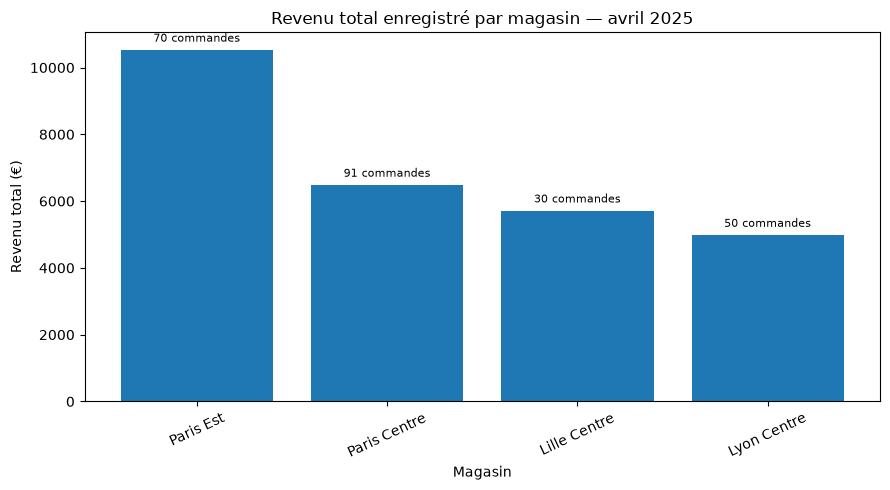

In [6]:
# Figure 1 : Revenu total par magasin
fig1_data = store_summary.sort_values("total_revenue_eur", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(fig1_data["store_name"].astype(str), fig1_data["total_revenue_eur"])
ax.set_title("Revenu total enregistré par magasin — avril 2025")
ax.set_xlabel("Magasin")
ax.set_ylabel("Revenu total (€)")
ax.tick_params(axis="x", rotation=25)
for bar, count in zip(bars, fig1_data["order_count"]):
    ax.annotate(
        f"{int(count)} commandes",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4), textcoords="offset points",
        ha="center", va="bottom", fontsize=8
    )
fig.tight_layout()
fig.savefig(OUT_DIR / "figure1_revenu_total_par_magasin.png", dpi=150, bbox_inches="tight")
plt.show()


**Notre interprétation**

Paris Est arrive en tête avec 10 528,90 € pour 70 commandes, devant Paris Centre avec 6 482,90 € pour 91 commandes. Avoir davantage de commandes ne garantit donc pas le revenu total le plus élevé. La comparaison porte seulement sur l'extrait disponible, dont la couverture peut varier selon les magasins.


**Figure 2 — Question, unité et agrégation**

Question : comment les montants des commandes se répartissent-ils selon le magasin ? L'unité d'observation est une commande. Les commandes sont regroupées par magasin pour représenter la médiane, les quartiles, la dispersion et les valeurs atypiques.


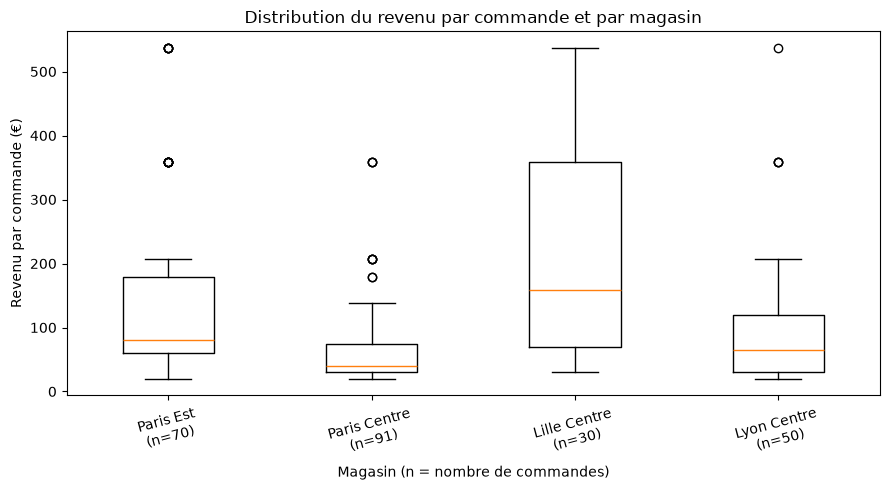

In [7]:
# Figure 2 — Distribution du revenu par commande
fig, ax = plt.subplots(figsize=(9, 5))
box_data = []
box_labels = []
for _, row in store_summary.iterrows():
    vals = analysis.loc[analysis["store_id"] == row["store_id"], "revenue_eur"].dropna()
    box_data.append(vals.to_numpy())
    box_labels.append(f"{row['store_name']}\n(n={len(vals)})")

ax.boxplot(box_data, tick_labels=box_labels, showfliers=True)
ax.set_title("Distribution du revenu par commande et par magasin")
ax.set_xlabel("Magasin (n = nombre de commandes)")
ax.set_ylabel("Revenu par commande (€)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(OUT_DIR / "figure2_distribution_revenu_commandes.png", dpi=150, bbox_inches="tight")
plt.show()



**Notre interprétation**

Lille Centre a la médiane la plus élevée, à 158,50 € par commande, contre 39,90 € pour Paris Centre. Les montants varient au sein de chaque magasin et certaines commandes apparaissent comme atypiques ; elles sont conservées car leur montant ne suffit pas à prouver une erreur. Les effectifs diffèrent, de 30 à 91 commandes, et le graphique décrit seulement les commandes de cet extrait.


**Figure 3 — Question, unité et agrégation**

Question : comment évolue le revenu quotidien enregistré dans chaque magasin ? L'unité représentée est un magasin pour une journée. Un point correspond à la somme des revenus des commandes enregistrées pour ce magasin à cette date.


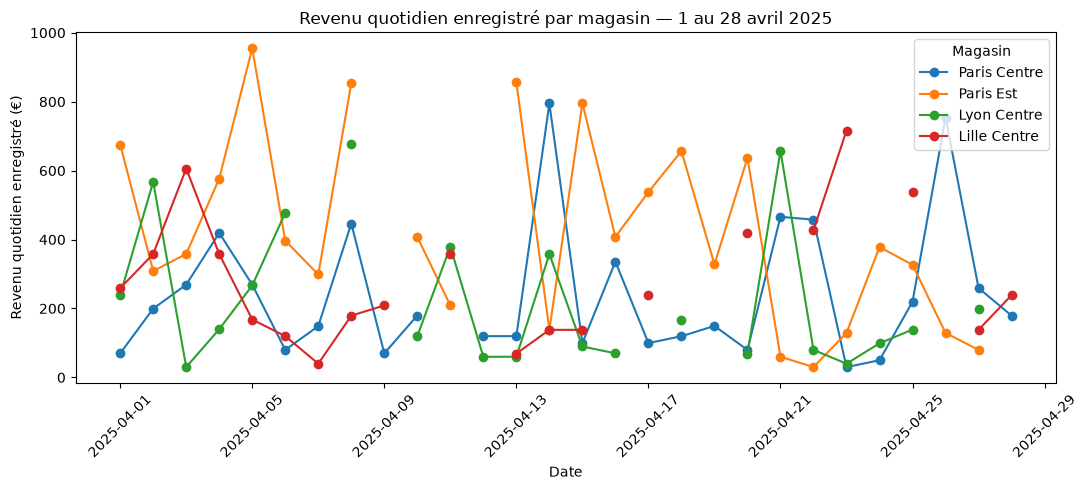

In [8]:
# Figure 3 — Évolution du revenu quotidien enregistré
fig, ax = plt.subplots(figsize=(11, 5))
for store_id in store_labels["store_id"].drop_duplicates():
    one_store = daily_revenue[daily_revenue["store_id"] == store_id].sort_values("date")
    name = one_store["store_name"].iloc[0]
    ax.plot(one_store["date"], one_store["revenue_eur"], marker="o", linewidth=1.5, label=name)

ax.set_title("Revenu quotidien enregistré par magasin — 1 au 28 avril 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Revenu quotidien enregistré (€)")
ax.legend(title="Magasin")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(OUT_DIR / "figure3_revenu_quotidien_par_magasin.png", dpi=150, bbox_inches="tight")
plt.show()



**Notre interprétation**

Le revenu enregistré varie d'un jour à l'autre : un total sur la période ne montre pas ces variations. Le nombre de jours avec des commandes analysées diffère aussi : 27 pour Paris Centre, 25 pour Paris Est, 22 pour Lyon Centre et 20 pour Lille Centre.

Le calendrier est commun du 1er au 28 avril 2025. Les jours sans commande dans l'extrait restent manquants (`NaN`), car une absence ne prouve ni zéro vente ni une fermeture du magasin.

Les trois figures se complètent : les barres comparent les totaux, les boîtes décrivent les montants des commandes et les courbes montrent les variations quotidiennes.


## 6. Write a decision brief
Write **six to eight sentences** addressed to the manager. Include:
- a clear answer to the original claim;
- at least two numerical results, with units and population;
- a distinction between total revenue and mean or median order revenue;
- a data-quality or integration limitation and a sample-coverage limitation;
- one plausible explanation labelled as a hypothesis;
- one proportionate next action and the extra data needed.

Avoid “Store X is best” without defining best. Do not claim causality, profitability or complete activity from this extract.

**Notre recommandation au responsable**


Le revenu total le plus élevé ne suffit pas à conclure qu'un magasin est le plus performant ni que son fonctionnement doit être reproduit partout. Sur les 241 commandes valides reliées à un magasin et à un produit, le revenu enregistré totalise 27 706,80 € du 1er au 28 avril 2025. Paris Est a le revenu total le plus élevé (10 528,90 € pour 70 commandes), alors que Lille Centre a la moyenne par commande la plus élevée (190,42 € pour 30 commandes). Le total mesure le revenu cumulé, tandis que la moyenne décrit le montant moyen d'une commande. Le nettoyage a mis 7 lignes invalides en revue et les jointures ont écarté 2 commandes sans référence correspondante, ce qui limite la population analysée. La couverture constitue une autre limite : il s'agit d'un extrait de commandes terminées et une date absente ne signifie pas zéro vente ni fermeture du magasin. Une hypothèse à vérifier est que les différences de nombre de commandes, de quantités ou de catégories de produits expliquent une partie des écarts. Nous recommandons de vérifier les lignes en revue puis de comparer les magasins sur une période plus complète, en collectant également les coûts, les horaires d'ouverture et la fréquentation pour mieux évaluer leur performance économique.


## 7. Export and reproduce
Save `store_summary.csv`, `category_summary.csv`, `reconciliation.csv`, `sales_review.csv` and `integration_review.csv` into `case_study_outputs/`. Save the three figures as PNG files. Use `index=False` for tables.

Before submitting:
- restart the kernel and run all cells from top to bottom;
- check that joins did not multiply rows and revenue totals reconcile;
- check that raw files remain unchanged;
- remove abandoned trials and explain all final decisions;
- make sure every member can explain one cleaning decision, one join control and every chart.

The deliverable is the entire completed notebook, including interpretations, not just the first figure.

In [9]:
# Exporter les tableaux et les trois graphiques
OUT_DIR.mkdir(exist_ok=True)

store_summary.to_csv(OUT_DIR / "store_summary.csv", index=False)
category_summary.to_csv(OUT_DIR / "category_summary.csv", index=False)
reconciliation.to_csv(OUT_DIR / "reconciliation.csv", index=False)
sales_review.to_csv(OUT_DIR / "sales_review.csv", index=False)
integration_review.to_csv(OUT_DIR / "integration_review.csv", index=False)

print("Fichiers exportés dans :", OUT_DIR.resolve())
for filename in [
    "store_summary.csv",
    "category_summary.csv",
    "reconciliation.csv",
    "sales_review.csv",
    "integration_review.csv",
    "figure1_revenu_total_par_magasin.png",
    "figure2_distribution_revenu_commandes.png",
    "figure3_revenu_quotidien_par_magasin.png",
]:
    print("-", filename, ":", (OUT_DIR / filename).exists())


Fichiers exportés dans : /Users/leoajas/Documents/M1 IBI 2026-2027/M1-INF4 - Atelier Python Data Science/repo_GroupeMontagne/notebooks/case_study_outputs
- store_summary.csv : True
- category_summary.csv : True
- reconciliation.csv : True
- sales_review.csv : True
- integration_review.csv : True
- figure1_revenu_total_par_magasin.png : True
- figure2_distribution_revenu_commandes.png : True
- figure3_revenu_quotidien_par_magasin.png : True


### OPTIONAL / IF TIME ALLOWS — Investigate product mix
Create a store × category table of revenue or order counts. Use a labelled heatmap or compare category shares within each store. State the denominator explicitly. Does the mix help explain different order amounts? Treat this as descriptive evidence, not a causal proof.